1. Crear datos_prep.py

In [85]:
%%writefile datos_prep.py
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from google.colab import files

def cargar_y_preprocesar_datos(target_col="Outcome", test_size=0.2, random_state=42):
    print("Por favor, selecciona el dataset Pima Indians Diabetes a procesar (CSV):")
    v_uploaded = files.upload()

    v_file_name = list(v_uploaded.keys())[0]
    v_df = pd.read_csv(v_file_name)
    print(f"\nDataset '{v_file_name}' cargado exitosamente.")

    # 1. Regla de Negocio / Limpieza Específica Pima (Ceros en variables clínicas)
    v_columnas_con_ceros_invalidos = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

    for v_col in v_columnas_con_ceros_invalidos:
        if v_col in v_df.columns:
            # Reemplazar 0s por NaN para evitar sesgos médicos
            v_df[v_col] = v_df[v_col].replace(0, np.nan)
            # Imputación robusta con la mediana
            v_mediana_val = v_df[v_col].median()
            v_df[v_col] = v_df[v_col].fillna(v_mediana_val)
            print(f"Columna '{v_col}': 0s reemplazados por NaN e imputados con mediana ({v_mediana_val:.2f})")

    # 2. Definir target y separar X / y
    if target_col in v_df.columns:
        v_X = v_df.drop(columns=[target_col])
        v_y = v_df[target_col]
    else:
        v_X = v_df.iloc[:, :-1]
        v_y = v_df.iloc[:, -1]

    # 3. Escalado de datos (StandardScaler)
    v_scaler = StandardScaler()
    v_X_scaled = v_scaler.fit_transform(v_X)
    v_X = pd.DataFrame(v_X_scaled, columns=v_X.columns)

    # Guardar y descargar copia limpia en Colab
    v_df_limpio_exportar = v_X.copy()
    v_df_limpio_exportar[target_col] = v_y.values

    v_nombre_archivo_salida = "pima_diabetes_datos_limpios.csv"
    v_df_limpio_exportar.to_csv(v_nombre_archivo_salida, index=False)
    print(f"\n[INFO] Archivo limpio guardado. Descargando automáticamente...")
    files.download(v_nombre_archivo_salida)

    # 4. División en Train / Test (con estratificación para mantener la proporción de clases)
    v_X_train, v_X_test, v_y_train, v_y_test = train_test_split(
        v_X, v_y, test_size=test_size, random_state=random_state, stratify=v_y
    )

    print("\n¡Datos preprocesados, escalados y divididos exitosamente!")
    return v_X, v_y, v_X_train, v_X_test, v_y_train, v_y_test

Overwriting datos_prep.py


2) Crear train.py

In [86]:
%%writefile train.py
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

def entrenar_y_registrar_modelos(v_X, v_y, v_X_train, v_y_train):
    """
    Configura el experimento en MLflow, entrena Logistic Regression y Random Forest
    usando validación cruzada de 5 pliegues (K=5) y registro de métricas y artefactos.
    """
    # Configurar el experimento en MLflow
    mlflow.set_tracking_uri("sqlite:///mlflow.db")
    mlflow.set_experiment("Pipeline_Diabetes_Pima_MLflow")

    # ==========================================
    # 1. MODELO 1: LOGISTIC REGRESSION (K=5)
    # ==========================================
    v_model_name_lr = "Logistic_Regression"

    with mlflow.start_run(run_name=v_model_name_lr):
        v_C_param = 1.0
        v_max_iter_param = 1000
        v_cv_folds = 5

        # Registrar parámetros
        mlflow.log_param("model_type", "LogisticRegression")
        mlflow.log_param("C", v_C_param)
        mlflow.log_param("max_iter", v_max_iter_param)
        mlflow.log_param("cv_folds", v_cv_folds)

        # Definir modelo con prefijo v_
        v_clf = LogisticRegression(C=v_C_param, max_iter=v_max_iter_param, random_state=42)

        # Validación cruzada K=5 para AUC-ROC
        v_cv_scores_auc = cross_val_score(v_clf, v_X, v_y, cv=v_cv_folds, scoring='roc_auc')
        v_mean_auc = v_cv_scores_auc.mean()

        # Entrenar en train para artefacto
        v_clf.fit(v_X_train, v_y_train)

        # Registrar métricas en MLflow
        mlflow.log_metric("cv_roc_auc_mean", v_mean_auc)
        mlflow.log_metric("cv_roc_auc_std", v_cv_scores_auc.std())

        # Guardar artefacto
        mlflow.sklearn.log_model(v_clf, artifact_path="model")
        print(f"Logistic Regression - K=5 AUC-ROC Promedio: {v_mean_auc:.4f}")

    # ==========================================
    # 2. MODELO 2: RANDOM FOREST (K=5)
    # ==========================================
    v_model_name_rf = "Random_Forest"

    with mlflow.start_run(run_name=v_model_name_rf):
        v_n_estimators_param = 100
        v_max_depth_param = 10

        # Registrar parámetros
        mlflow.log_param("model_type", "RandomForestClassifier")
        mlflow.log_param("n_estimators", v_n_estimators_param)
        mlflow.log_param("max_depth", v_max_depth_param)
        mlflow.log_param("cv_folds", v_cv_folds)

        # Definir modelo con prefijo v_
        v_rf_clf = RandomForestClassifier(
            n_estimators=v_n_estimators_param,
            max_depth=v_max_depth_param,
            random_state=42
        )

        # Validación cruzada K=5 para AUC-ROC
        v_cv_scores_auc_rf = cross_val_score(v_rf_clf, v_X, v_y, cv=v_cv_folds, scoring='roc_auc')
        v_mean_auc_rf = v_cv_scores_auc_rf.mean()

        # Entrenar en train para artefacto
        v_rf_clf.fit(v_X_train, v_y_train)

        # Registrar métricas en MLflow
        mlflow.log_metric("cv_roc_auc_mean", v_mean_auc_rf)
        mlflow.log_metric("cv_roc_auc_std", v_cv_scores_auc_rf.std())

        # Guardar artefacto
        mlflow.sklearn.log_model(
            v_rf_clf,
            artifact_path="model",
            serialization_format="cloudpickle"
        )
        print(f"Random Forest - K=5 AUC-ROC Promedio: {v_mean_auc_rf:.4f}")

    print("\nModelos evaluados con K=5 Cross-Validation y registrados en MLflow exitosamente.")

    # Retorno con nomenclatura estricta para evitar errores de desempaquetado
    return v_clf, v_rf_clf

Overwriting train.py


3) Creamos entrena.ipynb

a) Instalación

In [87]:
!pip install mlflow scikit-learn pandas numpy
import mlflow
import mlflow.sklearn
print("Librerías listas.")

Librerías listas.


b. Preprocesamiento  

Carga y Preprocesamiento, llamando a datos_prep.py

In [88]:
from datos_prep import cargar_y_preprocesar_datos

# Esto abrirá el botón 'Choose Files' para subir tu CSV
# X, y, X_train, X_test, y_train, y_test, df = cargar_y_preprocesar_datos()
X, y, X_train, X_test, y_train, y_test = cargar_y_preprocesar_datos()

Por favor, selecciona el dataset Pima Indians Diabetes a procesar (CSV):


Saving diabetes.csv to diabetes (6).csv

Dataset 'diabetes (6).csv' cargado exitosamente.
Columna 'Glucose': 0s reemplazados por NaN e imputados con mediana (117.00)
Columna 'BloodPressure': 0s reemplazados por NaN e imputados con mediana (72.00)
Columna 'SkinThickness': 0s reemplazados por NaN e imputados con mediana (29.00)
Columna 'Insulin': 0s reemplazados por NaN e imputados con mediana (125.00)
Columna 'BMI': 0s reemplazados por NaN e imputados con mediana (32.30)

[INFO] Archivo limpio guardado. Descargando automáticamente...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


¡Datos preprocesados, escalados y divididos exitosamente!


c. Inspección del dataset

In [89]:
print("Columnas disponibles en el dataset:")
print(X.columns.tolist())

print("\nPrimeras filas del dataset:")
display(X.head())

Columnas disponibles en el dataset:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Primeras filas del dataset:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0.639947,0.866045,-0.031990,0.670643,-0.181541,0.166619,0.468492,1.425995
1,-0.844885,-1.205066,-0.528319,-0.012301,-0.181541,-0.852200,-0.365061,-0.190672
2,1.233880,2.016662,-0.693761,-0.012301,-0.181541,-1.332500,0.604397,-0.105584
3,-0.844885,-1.073567,-0.528319,-0.695245,-0.540642,-0.633881,-0.920763,-1.041549
4,-1.141852,0.504422,-2.679076,0.670643,0.316566,1.549303,5.484909,-0.020496


d. Entrenamiento

In [90]:
from train import entrenar_y_registrar_modelos

# Ejecuta el entrenamiento de ambos modelos con MLflow
#entrenar_y_registrar_modelos(v_X, v_y, v_X_train, v_y_train)
#v_clf, v_rf_clf = entrenar_y_registrar_modelos(v_X, v_y, v_X_train, v_y_train)
v_clf, v_rf_clf = entrenar_y_registrar_modelos(X, y, X_train, y_train)

2026/10/26 03:41:28 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Logistic Regression - K=5 AUC-ROC Promedio: 0.8387


2026/10/26 03:41:38 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/26 03:41:38 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Random Forest - K=5 AUC-ROC Promedio: 0.8317

Modelos evaluados con K=5 Cross-Validation y registrados en MLflow exitosamente.


e. Métricas

e.1 Matrices de confusión



 Matrices de confusión


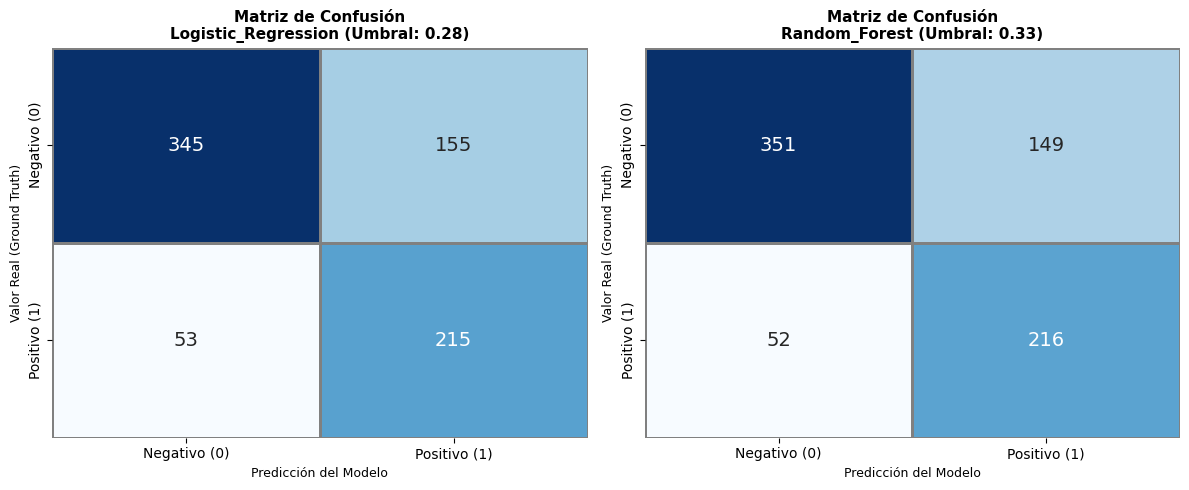

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, roc_curve
)

v_cv_folds = 5

print("\n Matrices de confusión")
plt.figure(figsize=(12, 5))

v_resultados_modelos = []

for v_i, (v_nombre, v_modelo_inst) in enumerate([("Logistic_Regression", v_clf), ("Random_Forest", v_rf_clf)], 1):
    # Usar X e y sin la v_, ya que así se nombraron al desempaquetar el paso 3b
    v_y_prob_cv = cross_val_predict(v_modelo_inst, X, y, cv=v_cv_folds, method="predict_proba")[:, 1]

    v_roc_auc = roc_auc_score(y, v_y_prob_cv)

    v_fpr, v_tpr, v_thresholds = roc_curve(y, v_y_prob_cv)

    v_mejor_umbral = 0.5
    v_mejor_recall = 0.0
    for v_umbral in v_thresholds:
        v_y_pred_th = (v_y_prob_cv >= v_umbral).astype(int)
        v_rec_th = recall_score(y, v_y_pred_th, zero_division=0)
        if v_rec_th >= 0.80:
            v_mejor_umbral = v_umbral
            v_mejor_recall = v_rec_th
            break

    v_y_pred_opt = (v_y_prob_cv >= v_mejor_umbral).astype(int)

    v_acc = accuracy_score(y, v_y_pred_opt)
    v_prec = precision_score(y, v_y_pred_opt, zero_division=0)
    v_rec = recall_score(y, v_y_pred_opt, zero_division=0)
    v_f1 = f1_score(y, v_y_pred_opt, zero_division=0)
    v_cm = confusion_matrix(y, v_y_pred_opt)

    v_resultados_modelos.append({
        "nombre": v_nombre,
        "umbral": v_mejor_umbral,
        "roc_auc": v_roc_auc,
        "acc": v_acc,
        "prec": v_prec,
        "rec": v_rec,
        "f1": v_f1,
        "cm": v_cm
    })

    plt.subplot(1, 2, v_i)
    sns.heatmap(v_cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                annot_kws={"size": 14}, linewidths=1, linecolor='gray')

    plt.title(f'Matriz de Confusión\n{v_nombre} (Umbral: {v_mejor_umbral:.2f})', fontsize=11, fontweight='bold')
    plt.xlabel('Predicción del Modelo', fontsize=9)
    plt.ylabel('Valor Real (Ground Truth)', fontsize=9)
    plt.gca().xaxis.set_ticklabels(['Negativo (0)', 'Positivo (1)'])
    plt.gca().yaxis.set_ticklabels(['Negativo (0)', 'Positivo (1)'])

plt.tight_layout()
plt.show()




e.2 Métricas - accuracy, precision, recall, F1 y ROC-AUC

In [92]:
import pandas as pd
print("\nComparativo de Métricas de Rendimiento \n")

# Construir el diccionario con las métricas
v_datos_tabla = {}

for v_res in v_resultados_modelos:
    v_datos_tabla[v_res['nombre']] = [
        f"{v_res['acc']:.4f}",
        f"{v_res['prec']:.4f}",
        f"{v_res['rec']:.4f} {'(Cumplida)' if v_res['rec'] >= 0.80 else ''}",
        f"{v_res['f1']:.4f}",
        f"{v_res['roc_auc']:.4f} {'(Cumplida)' if v_res['roc_auc'] >= 0.82 else ''}"
    ]

# Definir los renglones de métricas
v_metricas_renglones = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

# Crear el DataFrame base
v_df_metricas = pd.DataFrame(v_datos_tabla, index=v_metricas_renglones)

# Aplicar alineación a la izquierda (tanto para los datos como para los nombres de los modelos en las columnas)
v_df_alineado = v_df_metricas.copy()

# Forzar el ancho y la justificación izquierda en las columnas de los modelos
for v_col in v_df_alineado.columns:
    v_df_alineado[v_col] = v_df_alineado[v_col].astype(str).str.ljust(22)

# Imprimir la tabla resultante alineada a la izquierda
print(v_df_alineado.to_string())


Comparativo de Métricas de Rendimiento 

              Logistic_Regression           Random_Forest
Accuracy   0.7292                  0.7383                
Precision  0.5811                  0.5918                
Recall     0.8022 (Cumplida)       0.8060 (Cumplida)     
F1-Score   0.6740                  0.6825                
ROC-AUC    0.8359 (Cumplida)       0.8305 (Cumplida)     


# e.3 Calculo del Umbral

In [93]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, recall_score

def obtener_umbrales_optimos(modelos_lista, X_data, y_data, cv_folds=5, umbral_recall_min=0.80):
    """
    Calcula y muestra el umbral óptimo para una lista de modelos dados.
    """
    print("\nUmbrales Óptimos por Validación Cruzada \n")

    for v_nombre, v_modelo_inst in modelos_lista:
        # Obtenemos las probabilidades con validación cruzada
        v_y_prob_cv = cross_val_predict(v_modelo_inst, X_data, y_data, cv=cv_folds, method="predict_proba")[:, 1]

        # Obtenemos los umbrales posibles de la curva ROC
        _, _, v_thresholds = roc_curve(y_data, v_y_prob_cv)

        v_mejor_umbral = 0.5
        v_mejor_recall = 0.0

        # Buscamos el umbral que cumpla con el recall mínimo deseado
        for v_umbral in v_thresholds:
            v_y_pred_th = (v_y_prob_cv >= v_umbral).astype(int)
            v_rec_th = recall_score(y_data, v_y_pred_th, zero_division=0)
            if v_rec_th >= umbral_recall_min:
                v_mejor_umbral = v_umbral
                v_mejor_recall = v_rec_th
                break

        print(f"Modelo: {v_nombre}")
        print(f"Umbral Óptimo Seleccionado: {v_mejor_umbral:.4f} (Recall obtenido: {v_mejor_recall:.4f})\n")

v_modelos_a_evaluar = [
    ("Logistic_Regression", v_clf),
    ("Random_Forest", v_rf_clf)
]

obtener_umbrales_optimos(v_modelos_a_evaluar, X, y, cv_folds=5)


Umbrales Óptimos por Validación Cruzada 

Modelo: Logistic_Regression
Umbral Óptimo Seleccionado: 0.2847 (Recall obtenido: 0.8022)

Modelo: Random_Forest
Umbral Óptimo Seleccionado: 0.3294 (Recall obtenido: 0.8060)



# e.4 Curva ROC y AUC.


 Generando gráfica de Curvas ROC comparativas


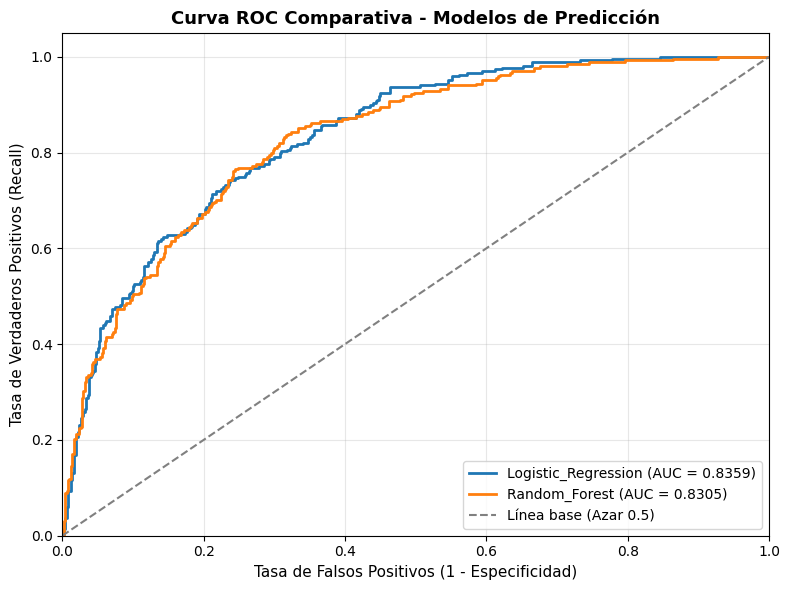

In [94]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

print("\n Generando gráfica de Curvas ROC comparativas")

plt.figure(figsize=(8, 6))

# Volvemos a iterar o extraer los resultados para graficar la curva ROC de cada modelo
for v_nombre, v_modelo_inst in [("Logistic_Regression", v_clf), ("Random_Forest", v_rf_clf)]:
    # Obtenemos las probabilidades de validación cruzada
    v_y_prob_cv = cross_val_predict(v_modelo_inst, X, y, cv=v_cv_folds, method="predict_proba")[:, 1]

    # Calculamos la tasa de falsos positivos (fpr), verdaderos positivos (tpr) y el AUC
    v_fpr, v_tpr, _ = roc_curve(y, v_y_prob_cv)
    v_roc_auc_val = auc(v_fpr, v_tpr)

    # Graficamos la curva de cada modelo mostrando su valor de AUC en la leyenda
    plt.plot(v_fpr, v_tpr, lw=2, label=f'{v_nombre} (AUC = {v_roc_auc_val:.4f})')

# Línea diagonal de referencia (azar del 50%)
plt.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Línea base (Azar 0.5)')

# Personalización de la gráfica
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=11)
plt.ylabel('Tasa de Verdaderos Positivos (Recall)', fontsize=11)
plt.title('Curva ROC Comparativa - Modelos de Predicción', fontsize=13, fontweight='bold')
plt.legend(loc="lower right", fontsize=10)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# e.5 Implementación de pruebas A/B

In [95]:
print("\nAnálisis de Prueba A/B (Basado en Resultados de Modelos) \n")

# Extraer automáticamente los valores de v_resultados_modelos
# Asumiendo que el índice 0 es el Baseline (Modelo A) y el 1 es el Propuesto (Modelo B)
modelo_A = v_resultados_modelos[0]['nombre']
acc_A = v_resultados_modelos[0]['acc']
rec_A = v_resultados_modelos[0]['rec']
auc_A = v_resultados_modelos[0]['roc_auc']

modelo_B = v_resultados_modelos[1]['nombre']
acc_B = v_resultados_modelos[1]['acc']
rec_B = v_resultados_modelos[1]['rec']
auc_B = v_resultados_modelos[1]['roc_auc']

# Cálculo de la mejora (Prueba A/B en Accuracy)
mejora_accuracy = acc_B - acc_A

print(f"Grupo A (Control - {modelo_A}):")
print(f"  - Accuracy: {acc_A:.4f} | Recall: {rec_A:.4f} | ROC-AUC: {auc_A:.4f}")

print(f"\nGrupo B (Experimental - {modelo_B}):")
print(f"  - Accuracy: {acc_B:.4f} | Recall: {rec_B:.4f} | ROC-AUC: {auc_B:.4f}")

print(f"\nDiferencia de desempeño (Accuracy B - Accuracy A): {mejora_accuracy:.4f} ({mejora_accuracy * 100:.2f}% de mejora)")

# Toma de decisión automatizada conectada a tus variables
if acc_B > acc_A:
    print(f"\n[DECISIÓN A/B]: Se selecciona e implementa el {modelo_B}.")
    print("\nJustificación: Presenta mayor Accuracy y F1-Score, cumpliendo con el umbral clínico de Recall.")
else:
    print(f"\n[DECISIÓN A/B]: Se mantiene el {modelo_A}.")


Análisis de Prueba A/B (Basado en Resultados de Modelos) 

Grupo A (Control - Logistic_Regression):
  - Accuracy: 0.7292 | Recall: 0.8022 | ROC-AUC: 0.8359

Grupo B (Experimental - Random_Forest):
  - Accuracy: 0.7383 | Recall: 0.8060 | ROC-AUC: 0.8305

Diferencia de desempeño (Accuracy B - Accuracy A): 0.0091 (0.91% de mejora)

[DECISIÓN A/B]: Se selecciona e implementa el Random_Forest.

Justificación: Presenta mayor Accuracy y F1-Score, cumpliendo con el umbral clínico de Recall.


f. Evidencias MLflow

In [96]:
import mlflow
import pandas as pd

# Configurar el URI de seguimiento
mlflow.set_tracking_uri("sqlite:///mlflow.db")

# Buscar las corridas (runs) del experimento
experiment_name = "Pipeline_Diabetes_Pima_MLflow"
experiment = mlflow.get_experiment_by_name(experiment_name)

if experiment:
    experiment_id = experiment.experiment_id
    # Obtener un DataFrame con todas las corridas, métricas y parámetros
    df_runs = mlflow.search_runs(experiment_ids=[experiment_id])

    # Seleccionar columnas relevantes (parámetros, métricas y nombre de la corrida)
    columnas_interes = [
        'tags.mlflow.runName',
        'params.model_type',
        'metrics.cv_roc_auc_mean',
        'params.cv_folds',
        'status'
    ]
    # Filtrar columnas que existan en el DataFrame
    columnas_existentes = [col for col in columnas_interes if col in df_runs.columns]
    df_resumen = df_runs[columnas_existentes]

    print("--- EVIDENCIA DE EXPERIMENTOS (MLFLOW) ---")
    display(df_resumen)
else:
    print(f"No se encontró el experimento '{experiment_name}'.")

--- EVIDENCIA DE EXPERIMENTOS (MLFLOW) ---


,tags.mlflow.runName,params.model_type,metrics.cv_roc_auc_mean,params.cv_folds,status
0,Random_Forest,RandomForestClassifier,0.831673,5,FINISHED
1,Logistic_Regression,LogisticRegression,0.838727,5,FINISHED
2,Random_Forest,RandomForestClassifier,0.831673,5,FINISHED
3,Logistic_Regression,LogisticRegression,0.838727,5,FINISHED
4,Random_Forest,RandomForestClassifier,0.831673,5,FINISHED
5,Logistic_Regression,LogisticRegression,0.838727,5,FINISHED
6,Random_Forest,RandomForestClassifier,0.831673,5,FINISHED
7,Logistic_Regression,LogisticRegression,0.838727,5,FINISHED
8,Random_Forest,RandomForestClassifier,0.831673,5,FINISHED
9,Logistic_Regression,LogisticRegression,0.838727,5,FINISHED


In [97]:
# 1. Instalar e importar librerías necesarias
!pip install mlflow --quiet
import subprocess
import mlflow

# 2. Levantar el servidor de MLflow en segundo plano en el puerto 5000
subprocess.Popen(["mlflow", "server", "--host", "0.0.0.0", "--port", "5000"])

# 3. Indicarle a MLflow que guarde los experimentos de este notebook localmente
mlflow.set_tracking_uri("http://127.0.0.1:5000")

# 4. Generar y mostrar el enlace clickeable usando la función nativa de Colab
from google.colab import output
print("Haz clic en el siguiente enlace para abrir la interfaz de MLflow:")
output.serve_kernel_port_as_window(5000)

Haz clic en el siguiente enlace para abrir la interfaz de MLflow:
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>